<a href="https://colab.research.google.com/github/luisavgonzalez27/ads-509-Final-Project/blob/main/02_MAUDE_Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAUDE Medical Device Adverse Event Data Collection

## Notebook 02 - MAUDE_Text_Classification

Uses FDA MAUDE narratives to classify Malfunction, Injury, or Death, using text embeddings.

* Examines narrative length and top bigrams by event type.
* Splits data into 80% training and 20% testing using stratified sampling.
* Converts narratives into numerical representations using a pretrained Sentence-BERT model.
* Trains and evaluates a multiclass logistic regression model using the Sentence-BERT embeddings.
* Compares the results with a weighted balanced logistic regression model.
* Misclassified reports are examined individually to better understand where the model has difficulty distinguishing between event types.

## Key Findings

- The standard Sentence-BERT + Logistic Regression achieved 95.3% accuracy and a 0.9083 macro F1-score on the 191-report test set.

- The standard model achieved F1-scores of 0.9852 for Malfunction, 0.9396 for Injury, and 0.8000 for Death.

- The balanced Sentence-BERT + Logistic Regression model achieved 98.4% accuracy and a 0.9808 macro F1-score.

- Class weighting increased Death recall from 66.7% to 100%. The balanced model correctly identified all 18 Death reports, ut resulted in decrease in Death precision from 100% to 94.7%.

- Error analysis: Some narratives contained language that could reasonably overlap between event types, while the standard model continued to misclassify several Death reports as Injury even when the narratives described a patient death.

- Overall, the results suggest that both data quality and class imbalance affect classification performance. After cleaning the narrative data, class weighting substantially improved minority-class detection while maintaining strong performance for Injury and Malfunction.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score)
from sklearn.feature_extraction.text import (CountVectorizer,ENGLISH_STOP_WORDS)


In [2]:
#load data
df = pd.read_csv("fda_cgm_reports_clean.csv")

print(df.shape)
print(df["event_type"].value_counts())
df.head(2)

(952, 10)
event_type
Malfunction    498
Injury         366
Death           88
Name: count, dtype: int64


,report_id,date_received,brand_name,generic_name,manufacturer,product_code,narrative,event_type,product_problems,patient_problems
0,3004753838-2020-038805,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION O...,Malfunction,"['Premature End-of-Life Indicator', 'Premature...","['No Consequences Or Impact To Patient', 'No C..."
1,3004753838-2020-038806,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR...,Malfunction,"['Wireless Communication Problem', 'Wireless C...","['No Consequences Or Impact To Patient', 'No C..."


Examine narrative length by event type

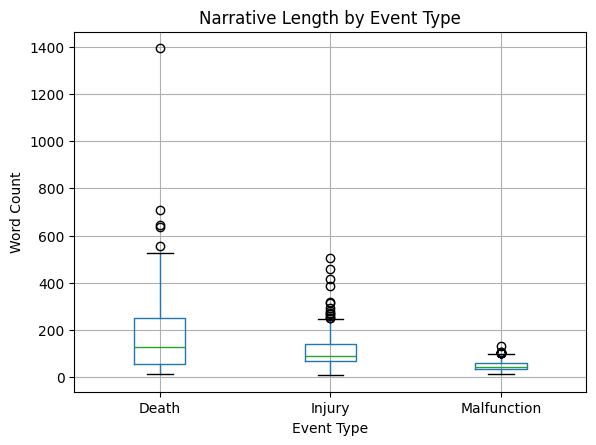

In [3]:
#plot narrative length by event type
df["word_count"] = df["narrative"].fillna("").str.split().str.len()
df["character_count"] = df["narrative"].fillna("").str.len()

df.boxplot(column="word_count", by="event_type")

plt.title("Narrative Length by Event Type")
plt.suptitle("")
plt.xlabel("Event Type")
plt.ylabel("Word Count")
plt.show()

Examine the top bigrams by event type

In [4]:
# remove filler words
custom_stop_words = list(
    ENGLISH_STOP_WORDS.union({
        "reported",
        "information",
        "available",
        "additional",
        "event",
        "provided",
        "occurred"}))

def get_top_bigrams(data, event_type, n=15):

    texts = data.loc[
        data["event_type"] == event_type,
        "narrative"
    ].dropna()

    vectorizer = CountVectorizer(
        stop_words=custom_stop_words,
        ngram_range=(2, 2),
        max_features=2000,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
    )

    X = vectorizer.fit_transform(texts)

    counts = X.sum(axis=0).A1
    bigrams = vectorizer.get_feature_names_out()

    frequencies = pd.DataFrame({
        "bigram": bigrams,
        "count": counts})

    return frequencies.sort_values(
        "count",
        ascending=False).head(n)

In [5]:
for event in ["Malfunction", "Injury", "Death"]:
    print(f"\nTop bigrams: {event}")
    display(get_top_bigrams(df, event))


Top bigrams: Malfunction


,bigram,count
82,cause determined,423
494,probable cause,376
411,medical intervention,370
345,injury medical,370
188,determined injury,275
613,signal loss,239
25,allegation confirmed,187
119,confirmed probable,182
397,loss hour,166
112,confirmation allegation,156



Top bigrams: Injury


,bigram,count
1194,mg dl,306
1636,sensor inserted,197
185,blood glucose,180
1708,skin reaction,177
239,cause determined,155
327,continuous glucose,137
1014,inserted abdomen,136
890,glucose bg,135
901,glucose monitor,133
1202,monitor cgm,123



Top bigrams: Death


,bigram,count
1565,mg dl,121
1620,passed away,62
1655,patient passed,49
1535,low alert,40
1940,urgent low,38
936,egv mg,35
1640,patient egvs,31
1840,sensor session,30
29,adc device,25
1717,probable cause,24


Modeling Phase

In [6]:
#drop unnecessary variables to avoid leakage
model_df = df[["narrative", "event_type"]].copy()

model_df = model_df.dropna(subset=["narrative", "event_type"])

print(model_df.shape)
print(model_df["event_type"].value_counts())

(952, 2)
event_type
Malfunction    498
Injury         366
Death           88
Name: count, dtype: int64


In [7]:
#Split the data into training and test set, using stratified sampling
X_train_text, X_test_text, y_train, y_test = train_test_split(
    model_df["narrative"],
    model_df["event_type"],
    test_size=0.20,
    random_state=20,
    stratify=model_df["event_type"])

print("Training observations:", len(X_train_text))
print("Testing observations:", len(X_test_text))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

#Save training and test datasets
train_df = pd.DataFrame({"narrative": X_train_text, "event_type": y_train}).reset_index(drop=True)

test_df = pd.DataFrame({"narrative": X_test_text, "event_type": y_test}).reset_index(drop=True)

train_df.to_csv("fda_cgm_train.csv", index=False)
test_df.to_csv("fda_cgm_test.csv", index=False)

Training observations: 761
Testing observations: 191

Training distribution:
event_type
Malfunction    398
Injury         293
Death           70
Name: count, dtype: int64

Testing distribution:
event_type
Malfunction    100
Injury          73
Death           18
Name: count, dtype: int64


In [8]:
#Turn medical narratives into embeddings
encoder = SentenceTransformer("all-MiniLM-L6-v2")

X_train_embeddings = encoder.encode(
    X_train_text.tolist(),
    batch_size=32,
    show_progress_bar=True)

X_test_embeddings = encoder.encode(
    X_test_text.tolist(),
    batch_size=32,
    show_progress_bar=True)

print(X_train_embeddings.shape)
print(X_test_embeddings.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

(761, 384)
(191, 384)


Model 1 - Logistic Regression

In [9]:
# Use embeddings in a logistic regression model
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_embeddings, y_train)

y_pred = lr.predict(X_test_embeddings)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=["Malfunction", "Injury", "Death"]))

Accuracy: 0.9529
Macro F1: 0.9083

Classification Report:
              precision    recall  f1-score   support

       Death     1.0000    0.6667    0.8000        18
      Injury     0.9211    0.9589    0.9396        73
 Malfunction     0.9709    1.0000    0.9852       100

    accuracy                         0.9529       191
   macro avg     0.9640    0.8752    0.9083       191
weighted avg     0.9546    0.9529    0.9503       191


Confusion Matrix:
[[100   0   0]
 [  3  70   0]
 [  0   6  12]]


In [10]:
#Examine reports that were incorrectly classifed
pd.set_option("display.max_colwidth", None)

results = pd.DataFrame({
    "narrative": X_test_text.values,
    "actual": y_test.values,
    "predicted": y_pred})

errors = results[results["actual"] != results["predicted"]]
errors

,narrative,actual,predicted
6,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 89 MG/DL, AND THE METER BG READING WAS 389 MG/DL. MULTIPLE ATTEMPTS WERE MADE BY TANDEM TECHNICAL SUPPORT TO FOLLOW-UP WITH THE CUSTOMER ON THE REPORTED ISSUE, BUT NO RESPONSE WAS RECEIVED.",Injury,Malfunction
9,"DECEDENT¿S ATTORNEY REPORTED TO DEXCOM THAT THE PATIENT¿S MOBILE APPLICATION/DISPLAY DEVICE ALLEGEDLY FAILED TO ALERT HIM TO DANGEROUS LOW GLUCOSE LEVELS FROM THE G6 SYSTEM. IT WAS ALLEGED THAT THE PATIENT SUFFERED SERIOUS INJURIES INCLUDING BUT NOT LIMITED TO HYPOGLYCEMIA. THE PATIENT WAS ALLEGEDLY INVOLVED IN A MOTOR VEHICLE ACCIDENT RESULTING IN HIS DEATH. ANALYSIS OF THE CGM DATA LOGS INDICATES THAT THE PATIENT WORE THE SENSOR FOR ONE DAY. THE SENSOR SESSION STARTED ON (B)(6) 2020 AT 2:53 AM WITH AN ESTIMATED GLUCOSE VALUE (EGV) OF 258 MG/DL, WHICH WAS ABOVE THE HIGH ALERT THRESHOLD OF 200 MG/DL. THE LAST RECORDED EGV, WHICH WAS BELOW 40 MG/DL, WAS AT 09:28 AM. THE DEVICE EXPERIENCED SENSOR ERROR FROM 09:33 AM TO 10:39 AM AND NO DEVICE PERFORMANCE DATA WAS RECORDED IN THE DATA LOGS AFTER THIS TIME. THE PATIENT¿S ALERT SETTINGS INDICATE THAT THE HIGH GLUCOSE ALERT WAS SET TO 200 MG/DL AND VIBRATE ONLY, THE LOW GLUCOSE ALERT WAS SET TO 70 MG/DL AND VIBRATE ONLY, THE ALWAYS SOUND FEATURE WAS DISABLED, AND THE REPEAT FEATURE WAS DISABLED. THE PERFORMANCE DATA LOGS SHOW THAT THE PREVIOUS SENSOR SESSION ENDED AS EXPECTED AFTER A FULL 10 DAYS ON (B)(6) 2020. THE PATIENT ACKNOWLEDGED AN ALERT THAT THE SENSOR WOULD EXPIRE SOON ON (B)(6) 2023 AT 10:30 AM AND THE SENSOR SESSION ENDED AT 1:28 PM. THE PATIENT DID NOT ACKNOWLEDGE THAT THE SENSOR SESSION ENDED UNTIL (B)(6) 2020 AT 10:13 PM. THE LAST ALERT ACKNOWLEDGEMENT WAS A ¿SENSOR SHUTOFF¿ ALERT AT 10:13 PM ON (B)(6) 2020, AFTER THE PREVIOUS SENSOR SESSION ENDED. DURING THE LAST SENSOR SESSION ON (B)(6) 2020, THE PATIENT¿S EGVS WERE ABOVE THE HIGH ALERT THRESHOLD OF 200 MG/DL FROM 02:53 AM TO 07:58 AM. THE PATIENT¿S EGVS DROPPED AND BY 08:48 AM THE EGVS BREACHED THE LOW ALERT THRESHOLD WITH AN EGV OF 64 MG/DL. THE APP DELIVERED URGENT LOW SOON ALERTS AT THE USER-SET MOBILE DEVICE VOLUME, 66 PERCENT, AND THE URGENT LOW ALERTS AT INCREASING VOLUME WITH EGVS DROPPING TO LESS THAN 40 MG/DL. THE DEVICE BEGAN EXPERIENCING SENSOR ERROR AT 09:33 AM AND AFTER THE SET 20-MINUTE THRESHOLD, THE APP DELIVERED SENSOR ERROR ALERTS FROM 09:53 AM TO 10:39 AM. NO ALERTS WERE ACKNOWLEDGED BY PATIENT DURING THIS TIME. NO DATA IS PRESENT IN THE LOGS AFTER 10:39 AM. THE ALLEGATION MADE BY DECEDENT¿S ATTORNEY THAT THE PATIENT¿S MOBILE APPLICATION/DISPLAY DEVICE ALLEGEDLY FAILED TO ALERT HIM TO DANGEROUSLY LOW GLUCOSE LEVELS FROM THE G6 SYSTEM COULD NOT BE CONFIRMED AND THE PROBABLE CAUSE WAS NOT DETERMINED. DEXCOM¿S LEGAL COUNSEL REQUESTED ADDITIONAL INFORMATION FROM DECEDENT¿S ATTORNEY AND NO FURTHER INFORMATION WAS PROVIDED.",Death,Injury
19,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 263 MG/DL, AND THE METER BG READING WAS 46 MG/DL. CUSTOMER ADDRESSED BG LEVEL WITH CARBOHYDRATES. A ROOT CAUSE COULD NOT BE DETERMINED. A REPLACEMENT SENSOR WAS SENT TO THE CUSTOMER.",Injury,Malfunction
20,"A LOW READING ISSUE WAS REPORTED WITH THE ABBOTT DIABETES CARE (ADC) DEVICE. THE CUSTOMER RECEIVED A SENSOR SCAN RESULT BETWEEN 2.7 MMOL/L AND 3.5 MMOL/L. IT IS UNKNOWN WHETHER THE PATIENT NOTICED A TREND ARROW ON THE DEVICE. DUE TO THE LOW READINGS, PERSONNEL AT THE PATIENT¿S LOCATION, BOSTED NURSING FACILITY, CONTACTED THE ON-CALL DOCTOR AND RECOMMENDED PROVIDING SUGAR AND HONEY TO THE PATIENT. THE PATIENT ALSO MANAGED TO CONSUME PROTEIN DRINKS. THE PATIENT EXPERIENCED SEVERAL SYMPTOMS, INCLUDING ANGER, SADNESS, FRUSTRATION, CRYING, URINARY INCONTINENCE, LACK OF APPETITE, FATIGU

Model 2 - Balanced Logistic Regression

In [11]:
#Compare logistic regression model to a balanced logistic regression model
lr_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

lr_balanced.fit(X_train_embeddings, y_train)

y_pred_balanced = lr_balanced.predict(X_test_embeddings)

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))

print("Macro F1:",round(f1_score(y_test, y_pred_balanced, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced,
        digits=4))
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_balanced,
        labels=["Malfunction", "Injury", "Death"]))

Accuracy: 0.9843
Macro F1: 0.9808

Classification Report:
              precision    recall  f1-score   support

       Death     0.9474    1.0000    0.9730        18
      Injury     0.9861    0.9726    0.9793        73
 Malfunction     0.9900    0.9900    0.9900       100

    accuracy                         0.9843       191
   macro avg     0.9745    0.9875    0.9808       191
weighted avg     0.9845    0.9843    0.9843       191


Confusion Matrix:
[[99  1  0]
 [ 1 71  1]
 [ 0  0 18]]


In [12]:
#Examine reports that were incorrectly classifed using the balanced regression model
pd.set_option("display.max_colwidth", None)

results_balanced = pd.DataFrame({
    "narrative": X_test_text.values,
    "actual": y_test.values,
    "predicted": y_pred_balanced})

errors_balanced = results_balanced[results_balanced["actual"] != results_balanced["predicted"]]
errors_balanced

,narrative,actual,predicted
6,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 89 MG/DL, AND THE METER BG READING WAS 389 MG/DL. MULTIPLE ATTEMPTS WERE MADE BY TANDEM TECHNICAL SUPPORT TO FOLLOW-UP WITH THE CUSTOMER ON THE REPORTED ISSUE, BUT NO RESPONSE WAS RECEIVED.",Injury,Malfunction
87,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 67 MG/DL, AND THE METER BG READING WAS 123 MG/DL. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED. TANDEM TECHNICAL SUPPORT INSTRUCTED THE CUSTOMER TO ENTER CALIBRATION BG VALUES TO ADDRESS THE ISSUE.",Malfunction,Injury
176,"IT WAS REPORTED THAT THERE WERE INTERMITTENT INACCURACIES BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. MULTIPLE ATTEMPTS WERE MADE BY TANDEM TECHNICAL SUPPORT TO FOLLOW-UP WITH THE CUSTOMER ON THE REPORTED ISSUE, BUT NO RESPONSE WAS RECEIVED. VOLUNTARY MEDWATCH RECEIVED (B)(6) 2020 VIA US MAIL REPORTED: I HAVE A TANDEM TSLIM MEDICAL INSULIN PUMP WITH A DEXCOM G6 CONTINUOUS GLUCOSE MONITORING AND I USE TANDEM'S CONTROL IQ. I AM USING THE DEVICE AS ADVERTISED AND INSTRUCTED BY TANDEM. THE DEVICE IS JEOPARDIZING MY LIFE BY CONTINUING TO DELIVER INSULIN WHEN NOT NEEDED AND CAUSSING MY GLUCOSE TO DROP DANGEROUSLY FORCING ME TO CONSUME CARBOHYDRATES TO RETURN MY GLUCOSE BACK TO NORMAL LEVELS. HOWEVER, WHEN I CONSUME CARBOHYDRATES THE PUMP STARTS DELIVERING UNNECESSARY INSULIN SO I AM IN A CONSTANT ROLLER COASTER RIDE. FACT, THE TSLIM PUMP LOOSES DATA FOR UNKNOWN REASONS. TANDEM ADVERTISES THAT THE PUMP ""PREDICTS GLUCOSE 30 MINUTES AHEAD"" AND ""SUSPENDS INSULIN TO HELP AVOID THE LOW"" AND IN MY UPLOADED DOCUMENTATION, YOU CAN SEE THAT PREDICTION IS NOT HAPPENING. THEREFORE, THE PUMP IS NOT FUNCTIONING AS ADVERTISED. THE TANDEM PUMP READS MY GLUCOSE FROM THE DEXCOM G6 TO FUNCTION. HOWEVER THE GLUCOSE READINGS ARE NOT ACCURATE. FACT THE READINGS ARE 20% OUT OF CALIBRATION CONSTANTLY. IF I USE THE DEXCOM G6 MONITOR, THE GLUCOSE READINGS ARE LESS THAN 10% OUT OF CALIBRATION, FAR MORE ACCURATE THAN THE TANDEM PUMP. WITH CONTROL IQ DISABLED, I AM EXPERIENCING INSULIN DELIVERY ISSUES. THE PUMP SHOWS INSULIN DELIVERED, HOWEVER, I AM NOT RECEIVING THE AMOUNT OF INSULIN THE PUMP SHOWS DELIVERED. AS A RESULT, I AM NO LONGER USING THE DEFECTIVE PUMP AND HAVE RETURNED TO USING AN INSULIN PEN. SINCE I HAVE RETURNED TO USING THE INSULIN PEN, MY GLUCOSE IS BACK TO A NORMAL LEVEL AND I AM NOT ON THE ROLLER COASTER RIDE (HIGH TO LOW TO HIGH).",Injury,Death
